# Feature-ablation experiment for cross-network robustness

## Research question

Do high-drift or laboratory-context features improve performance only inside their source environment, and does excluding them produce a more transferable binary intrusion detector?

The experiment holds the model and training budget constant while changing only the predictor set. Feature selection is performed on training partitions only; the chronological test partitions remain untouched.

## 1. Setup and evaluation policy

**Why we are doing this.** KS analysis showed that several feature distributions change between years, while the EDA identified ports and TCP-window fields as possible laboratory shortcuts. An ablation test is needed to determine whether those signals actually cause transfer failure.

**Business relevance.** A slightly lower within-network score can be an acceptable tradeoff if the detector retains more attacks and produces fewer false alarms when deployed at another customer network.

In [1]:
import glob, os, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_rows', 100)
ROOT = Path('../Data')
D17 = ROOT / 'archive' / 'CICIDS2017_improved'
SAMPLE18 = ROOT / 'sample_2018_stratified.csv.gz'
RS, TRAIN_BUDGET, KS_THRESHOLD = 42, 300_000, 0.50
OUTPUT_DIR = Path(os.environ.get('ROBUSTNESS_OUTPUT_DIR', 'results'))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
def signed_log(x): return np.sign(x) * np.log1p(np.abs(x))
def make_model():
    return make_pipeline(FunctionTransformer(signed_log), SimpleImputer(strategy='median'),
        StandardScaler(), LogisticRegression(C=1.0, penalty='l2', solver='lbfgs',
        max_iter=1000, class_weight='balanced', random_state=RS))

/Users/ranga/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/8p/7ywd43m12fz07p58l3312vqh0000gn/T/matplotlib-azztwbzx because there was an issue with the default path (/Users/ranga/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.



Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/ranga/.cache/fontconfig
	/Users/ranga/.fontconfig


Matplotlib is building the font cache; this may take a moment.


## 2. Load, harmonize, and split the datasets

Identifiers, timestamps, labels, and file metadata are excluded from predictors. Attempted attacks follow the existing project policy and are assigned to the benign class. Each original label is split chronologically: the earliest 80% is used for training and the latest 20% for testing.

In [2]:
files17 = sorted(glob.glob(str(D17 / '*.csv')))
if not files17: raise FileNotFoundError(f'No CICIDS2017 CSV files found under {D17}')
if not SAMPLE18.exists(): raise FileNotFoundError('Run the download and EDA sample-building notebooks first.')
raw17 = pd.concat([pd.read_csv(p) for p in files17], ignore_index=True)
raw18 = pd.read_csv(SAMPLE18)
metadata = {'id','Flow ID','Src IP','Dst IP','Src Port','Timestamp','Attempted Category','Label','file'}
FEATURES = sorted(c for c in (set(raw17.columns) & set(raw18.columns)) - metadata
                  if pd.api.types.is_numeric_dtype(raw17[c]) and pd.api.types.is_numeric_dtype(raw18[c]))
def prepare(raw, year):
    x = raw[FEATURES].replace([np.inf, -np.inf], np.nan).astype('float32').copy()
    x['raw_label'] = raw.Label.astype(str).values
    x['target'] = ((x.raw_label != 'BENIGN') & ~x.raw_label.str.endswith(' - Attempted')).astype('int8')
    x['ts'] = pd.to_datetime(raw.Timestamp, errors='coerce').values
    x['year'] = year
    return x.dropna(subset=['ts']).drop_duplicates(subset=FEATURES + ['target']).reset_index(drop=True)
data17, data18 = prepare(raw17, '2017'), prepare(raw18, '2018')
del raw17, raw18
def chronological_split(frame):
    rank = frame.groupby('raw_label').ts.rank(method='first', pct=True)
    return frame.index[rank <= .80].to_numpy(), frame.index[rank > .80].to_numpy()
tr17, te17 = chronological_split(data17)
tr18, te18 = chronological_split(data18)
display(pd.DataFrame({'features':[len(FEATURES),len(FEATURES)], 'train rows':[len(tr17),len(tr18)],
                      'test rows':[len(te17),len(te18)]}, index=['2017','2018']))

,features,train rows,test rows
2017,83,1469282,367333
2018,83,268654,67174


## 3. Calculate training-only per-class KS drift

For each binary class—benign and effective attack—the 2017 and 2018 training distributions are compared. A feature is marked high drift when its mean class-specific KS statistic is at least `KS_THRESHOLD`. This is intentionally a declared experimental rule, not a universal production threshold.

In [3]:
rng = np.random.default_rng(RS)
def bounded_values(frame, indices, target, feature, n=20_000):
    values = frame.loc[np.intersect1d(indices, frame.index[frame.target.eq(target)]), feature].dropna().to_numpy()
    return rng.choice(values, n, replace=False) if len(values) > n else values
ks_rows = []
for feature in FEATURES:
    row = {'feature': feature}
    for target, label in [(0,'benign'),(1,'attack')]:
        a = bounded_values(data17, tr17, target, feature)
        b = bounded_values(data18, tr18, target, feature)
        row[f'ks_{label}'] = ks_2samp(a, b).statistic if len(a) and len(b) else np.nan
    ks_rows.append(row)
ks_table = pd.DataFrame(ks_rows)
ks_table['mean_ks'] = ks_table[['ks_benign','ks_attack']].mean(axis=1)
ks_table['high_drift'] = ks_table.mean_ks.ge(KS_THRESHOLD)
ks_table = ks_table.sort_values('mean_ks', ascending=False)
display(ks_table.head(25).style.format({'ks_benign':'{:.3f}','ks_attack':'{:.3f}','mean_ks':'{:.3f}'}))
ks_table.to_csv(OUTPUT_DIR / '07_training_only_ks_statistics.csv', index=False)
HIGH_DRIFT = ks_table.loc[ks_table.high_drift, 'feature'].tolist()
print(f'{len(HIGH_DRIFT)} of {len(FEATURES)} features meet the KS threshold of {KS_THRESHOLD:.2f}.')

,feature,ks_benign,ks_attack,mean_ks,high_drift
44,Fwd IAT Min,0.231,0.697,0.464,False
71,RST Flag Count,0.281,0.578,0.430,False
19,Bwd Packet Length Std,0.152,0.644,0.398,False
79,Total Length of Bwd Packet,0.130,0.659,0.395,False
68,Packet Length Std,0.121,0.655,0.388,False
16,Bwd Packet Length Max,0.119,0.653,0.386,False
69,Packet Length Variance,0.124,0.645,0.384,False
65,Packet Length Max,0.114,0.652,0.383,False
73,Subflow Bwd Bytes,0.104,0.657,0.381,False
23,Bwd Segment Size Avg,0.108,0.645,0.376,False


0 of 83 features meet the KS threshold of 0.50.


## 4. Define the ablation groups

The environment group is defined from the EDA findings rather than selected from test performance. It covers destination port, protocol, TCP initial-window values, and flag-count fields that can identify the laboratory host or network stack. Only names present in the shared schema are removed.

In [4]:
LAB_CONTEXT_CANDIDATES = {
 'Dst Port','Protocol','FWD Init Win Bytes','Bwd Init Win Bytes','Init Fwd Win Bytes','Init Bwd Win Bytes',
 'Fwd PSH Flags','Bwd PSH Flags','Fwd URG Flags','Bwd URG Flags','FIN Flag Count','SYN Flag Count',
 'RST Flag Count','PSH Flag Count','ACK Flag Count','URG Flag Count','CWR Flag Count','ECE Flag Count'
}
LAB_CONTEXT = sorted(set(FEATURES) & LAB_CONTEXT_CANDIDATES)
feature_sets = {
 'All features': FEATURES,
 'Without high-KS': [f for f in FEATURES if f not in HIGH_DRIFT],
 'Without lab context': [f for f in FEATURES if f not in LAB_CONTEXT],
 'Without both': [f for f in FEATURES if f not in set(HIGH_DRIFT) | set(LAB_CONTEXT)],
}
display(pd.DataFrame({'feature set':feature_sets.keys(), 'features retained':[len(v) for v in feature_sets.values()]}))
print('High-KS features:', HIGH_DRIFT)
print('Lab-context features:', LAB_CONTEXT)

,feature set,features retained
0,All features,83
1,Without high-KS,83
2,Without lab context,67
3,Without both,67


High-KS features: []
Lab-context features: ['ACK Flag Count', 'Bwd Init Win Bytes', 'Bwd PSH Flags', 'Bwd URG Flags', 'CWR Flag Count', 'Dst Port', 'ECE Flag Count', 'FIN Flag Count', 'FWD Init Win Bytes', 'Fwd PSH Flags', 'Fwd URG Flags', 'PSH Flag Count', 'Protocol', 'RST Flag Count', 'SYN Flag Count', 'URG Flag Count']


## 5. Train controlled mixed-network models

All variants use the same mixed training rows, preprocessing, estimator, and classification threshold. Only the available predictor columns change, which isolates the effect of feature removal.

In [5]:
def stratified_sample(frame, indices, size, seed):
    idx = np.asarray(indices); y = frame.target.iloc[idx].to_numpy(); local = np.random.default_rng(seed); out=[]
    for target in [0,1]:
        group=idx[y==target]; take=min(len(group), int(round(size*(len(group)/len(idx)))))
        out.append(local.choice(group, take, replace=False))
    result=np.concatenate(out); local.shuffle(result); return result
budget = min(TRAIN_BUDGET, len(tr17), len(tr18))
s17 = stratified_sample(data17, tr17, budget, RS)
s18 = stratified_sample(data18, tr18, budget, RS+1)
train_frame = pd.concat([data17.iloc[s17], data18.iloc[s18]], ignore_index=True)
test_sets = {'2017 test':data17.iloc[te17], '2018 test':data18.iloc[te18]}
rows=[]
for set_name, columns in feature_sets.items():
    if not columns: raise ValueError(f'{set_name} removed every feature; lower KS_THRESHOLD.')
    model=make_model(); started=time.perf_counter(); model.fit(train_frame[columns], train_frame.target); elapsed=time.perf_counter()-started
    for test_name, test in test_sets.items():
        pred=model.predict(test[columns]); score=model.predict_proba(test[columns])[:,1]
        precision, recall, f1, _ = precision_recall_fscore_support(test.target,pred,labels=[0,1],zero_division=0)
        tn,fp,fn,tp=confusion_matrix(test.target,pred,labels=[0,1]).ravel()
        rows.append({'feature_set':set_name,'test_dataset':test_name,'features':len(columns),
          'macro_f1':f1.mean(),'attack_precision':precision[1],'attack_recall':recall[1],
          'attack_f1':f1[1],'false_alarm_rate':fp/(fp+tn),'roc_auc':roc_auc_score(test.target,score),
          'tn':tn,'fp':fp,'fn':fn,'tp':tp,'fit_seconds':elapsed})
results=pd.DataFrame(rows)
results.to_csv(OUTPUT_DIR / '07_feature_ablation_results.csv',index=False)
display(results.sort_values(['test_dataset','macro_f1'],ascending=[True,False]).round(4))

,feature_set,test_dataset,features,macro_f1,attack_precision,attack_recall,attack_f1,false_alarm_rate,roc_auc,tn,fp,fn,tp,fit_seconds
0,All features,2017 test,83,0.9628,0.9027,0.9864,0.9427,0.0298,0.9923,278368,8552,1097,79316,21.0765
2,Without high-KS,2017 test,83,0.9628,0.9027,0.9864,0.9427,0.0298,0.9923,278368,8552,1097,79316,21.6709
4,Without lab context,2017 test,67,0.9452,0.8565,0.9848,0.9162,0.0462,0.9934,273657,13263,1219,79194,23.4117
6,Without both,2017 test,67,0.9452,0.8565,0.9848,0.9162,0.0462,0.9934,273657,13263,1219,79194,23.5321
1,All features,2018 test,83,0.9676,0.9501,0.9777,0.9637,0.0392,0.9891,36602,1493,649,28430,21.0765
3,Without high-KS,2018 test,83,0.9676,0.9501,0.9777,0.9637,0.0392,0.9891,36602,1493,649,28430,21.6709
5,Without lab context,2018 test,67,0.9432,0.9169,0.9573,0.9367,0.0662,0.9777,35573,2522,1243,27836,23.4117
7,Without both,2018 test,67,0.9432,0.9169,0.9573,0.9367,0.0662,0.9777,35573,2522,1243,27836,23.5321


## 6. Compare robustness and make the decision

Ablation is beneficial when performance becomes more consistent across both years without an operationally unacceptable false-alarm increase. The gap table measures stability; it should be interpreted together with the absolute metrics.

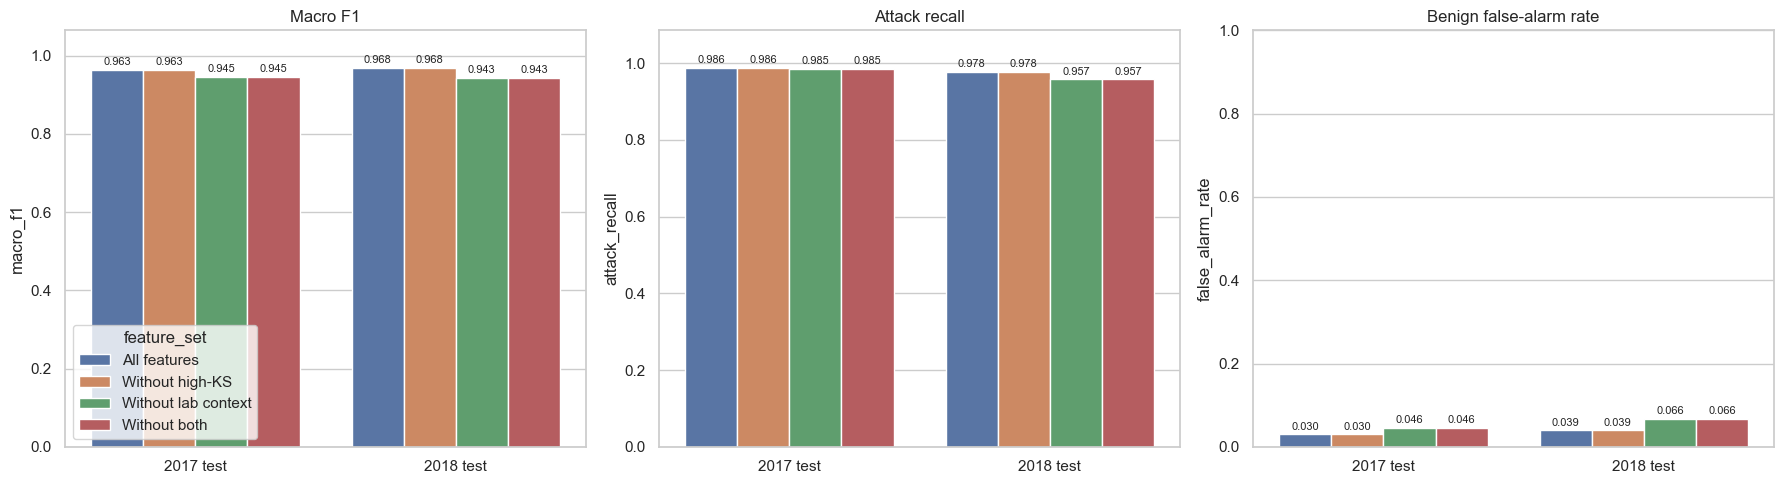

,macro_f1_gap,attack_recall_gap,worst_year_macro_f1,worst_year_attack_recall,worst_year_false_alarm_rate
feature_set,,,,,
All features,0.0048,0.0087,0.9628,0.9777,0.0392
Without high-KS,0.0048,0.0087,0.9628,0.9777,0.0392
Without both,0.0020,0.0276,0.9432,0.9573,0.0662
Without lab context,0.0020,0.0276,0.9432,0.9573,0.0662


Candidate selected by worst-year macro F1, then attack recall: All features
This is experimental evidence, not an automatic deployment approval; review false alarms and per-family recall before adoption.


In [6]:
fig,axes=plt.subplots(1,3,figsize=(18,5))
for ax,(metric,title) in zip(axes,[('macro_f1','Macro F1'),('attack_recall','Attack recall'),('false_alarm_rate','Benign false-alarm rate')]):
    sns.barplot(data=results,x='test_dataset',y=metric,hue='feature_set',ax=ax)
    ax.set_title(title); ax.set_xlabel(''); ax.set_ylim(0,max(1.0,results[metric].max()*1.1))
    for container in ax.containers: ax.bar_label(container,fmt='%.3f',fontsize=8,padding=2)
axes[1].get_legend().remove(); axes[2].get_legend().remove(); plt.tight_layout(); plt.show()
wide=results.pivot(index='feature_set',columns='test_dataset',values=['macro_f1','attack_recall','false_alarm_rate'])
gaps=pd.DataFrame({
 'macro_f1_gap':(wide[('macro_f1','2017 test')]-wide[('macro_f1','2018 test')]).abs(),
 'attack_recall_gap':(wide[('attack_recall','2017 test')]-wide[('attack_recall','2018 test')]).abs(),
 'worst_year_macro_f1':wide['macro_f1'].min(axis=1),
 'worst_year_attack_recall':wide['attack_recall'].min(axis=1),
 'worst_year_false_alarm_rate':wide['false_alarm_rate'].max(axis=1)
}).sort_values(['worst_year_macro_f1','worst_year_attack_recall'],ascending=False)
display(gaps.round(4))
best=gaps.index[0]
print(f'Candidate selected by worst-year macro F1, then attack recall: {best}')
print('This is experimental evidence, not an automatic deployment approval; review false alarms and per-family recall before adoption.')

## Takeaway

Use the generated comparison to determine whether high-drift or laboratory-context variables create brittle performance. Removing a feature group is justified only when the reduced model improves worst-year performance or materially narrows the cross-year gap while keeping the false-alarm rate operationally acceptable. A future extension should repeat the test on an entirely unseen third network and add per-family recall analysis.